## PJM Hourly Energy Consumption Data ##
PJM Interconnection LLC (PJM) is a regional transmission organization (RTO) in the United States. It is part of the Eastern Interconnection grid operating an electric transmission system serving all or parts of Delaware, Illinois, Indiana, Kentucky, Maryland, Michigan, New Jersey, North Carolina, Ohio, Pennsylvania, Tennessee, Virginia, West Virginia, and the District of Columbia.

The hourly power consumption data comes from PJM's website and are in megawatts (MW).

The regions have changed over the years so data may only appear for certain dates per region.

In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

In [ ]:
import importlib.util
import subprocess
import sys

paquetes = {
    "numpy": "numpy",
    "pandas": "pandas",
    "torch": "torch",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "plotly": "plotly",
    "IPython": "ipython",
}

faltantes = [
    paquete
    for modulo, paquete in paquetes.items()
    if importlib.util.find_spec(modulo) is None
]

if faltantes:
    print(f"Instalando paquetes faltantes: {', '.join(faltantes)}")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *faltantes
    ])
else:
    print("Todos los paquetes necesarios ya están instalados.")

## Preprocesamiento y entendimiento de los datos ##

In [101]:
data = pd.read_csv('PJME_hourly.csv')

In [ ]:
##Preprocesamiento de datos temporales

#Convertir la columna "Datetime" a tipo datetime
data["Datetime"] = pd.to_datetime(data["Datetime"], errors="coerce")
# Convertir PJME_MW a dato numérico
data["PJME_MW"] = pd.to_numeric(data["PJME_MW"], errors="coerce")
#Organizar los datos cronologicamente y establecer la columna "Datetime" como índice
data = data.sort_values("Datetime").set_index("Datetime")
# Crear variables temporales para las particiones
data["Year"] = data.index.year
data["Quarter"] = data.index.quarter
data["Month"] = data.index.month
data["Week"] = data.index.isocalendar().week.astype(int)
data["DayOfWeek"] = data.index.dayofweek
data["Hour"] = data.index.hour

# Nombres para las gráficas
dias = ["Lunes", "Martes", "Miércoles", "Jueves",
        "Viernes", "Sábado", "Domingo"]

meses = ["Enero", "Febrero", "Marzo", "Abril",
         "Mayo", "Junio", "Julio", "Agosto",
         "Septiembre", "Octubre", "Noviembre", "Diciembre"]


C:\Users\Usuario\AppData\Local\Temp\ipykernel_7628\2521502920.py:14: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  data["DayOfWeek"] = data.index.dayofweek


In [103]:
print(data.head())

                     PJME_MW  Year  Quarter  Month  Week  DayOfWeek  Hour
Datetime                                                                 
2002-01-01 01:00:00  30393.0  2002        1      1     1          1     1
2002-01-01 02:00:00  29265.0  2002        1      1     1          1     2
2002-01-01 03:00:00  28357.0  2002        1      1     1          1     3
2002-01-01 04:00:00  27899.0  2002        1      1     1          1     4
2002-01-01 05:00:00  28057.0  2002        1      1     1          1     5


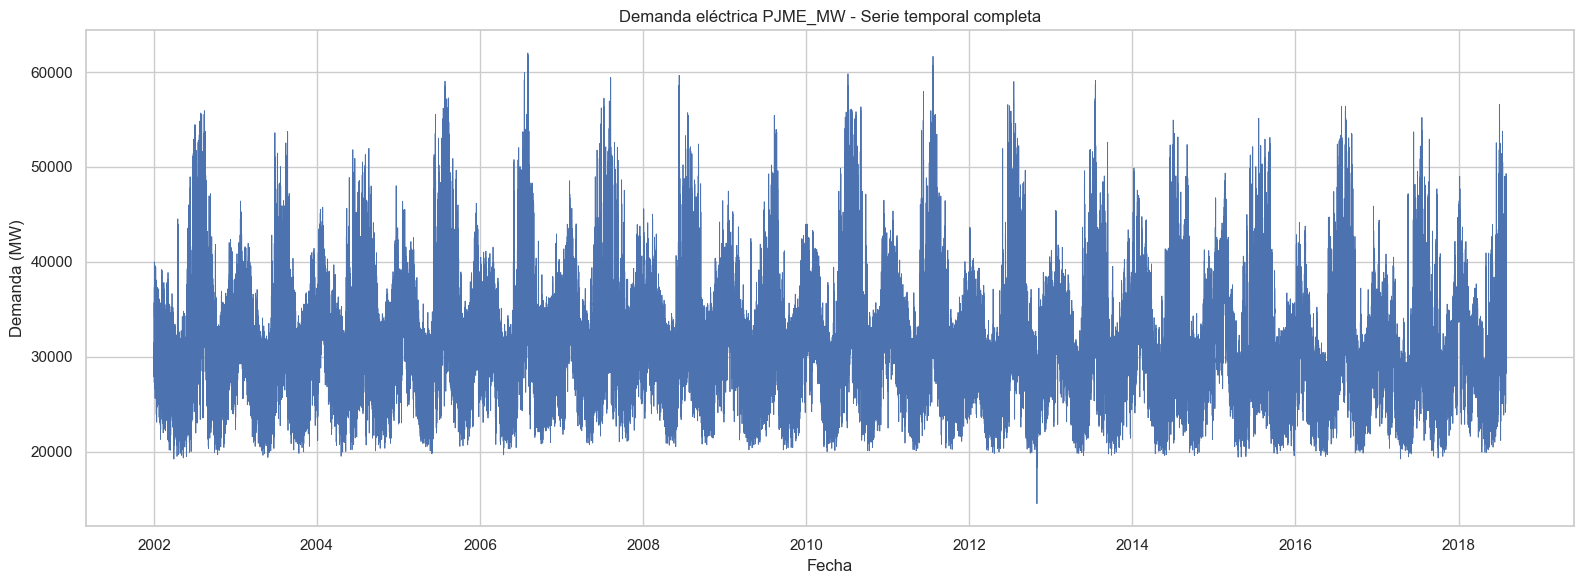

In [104]:
# Serie temporal completa de la demanda eléctrica PJME_MW

plt.figure(figsize=(16, 6))
plt.plot(data.index, data["PJME_MW"], linewidth=0.6)
plt.title("Demanda eléctrica PJME_MW - Serie temporal completa")
plt.xlabel("Fecha")
plt.ylabel("Demanda (MW)")
plt.tight_layout()
plt.show()

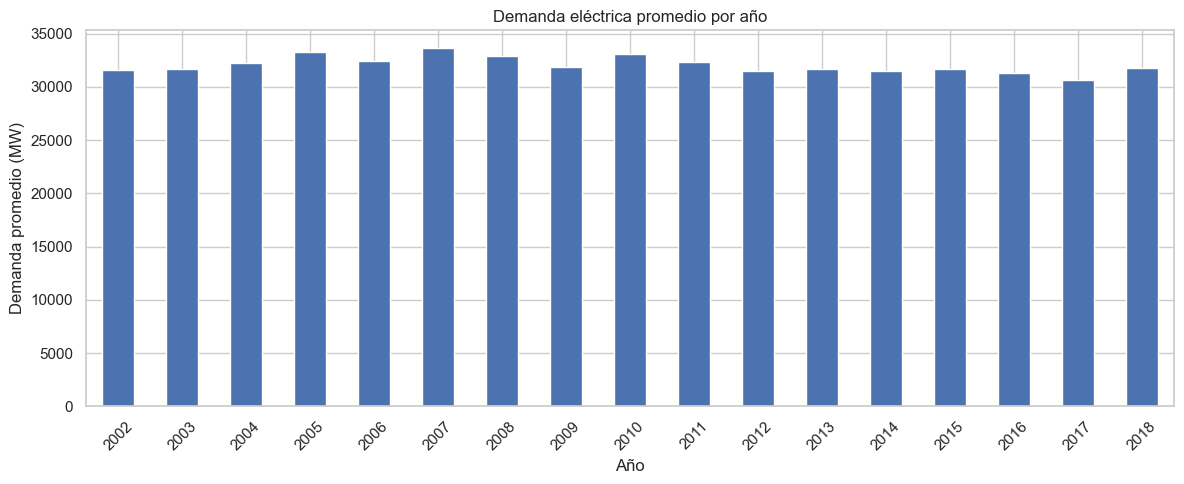

In [106]:
#PARTICIÓN ANUAL Promedio de demanda por año

anual = data.groupby("Year")["PJME_MW"].mean()

plt.figure(figsize=(12, 5))
anual.plot(kind="bar")
plt.title("Demanda eléctrica promedio por año")
plt.xlabel("Año")
plt.ylabel("Demanda promedio (MW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


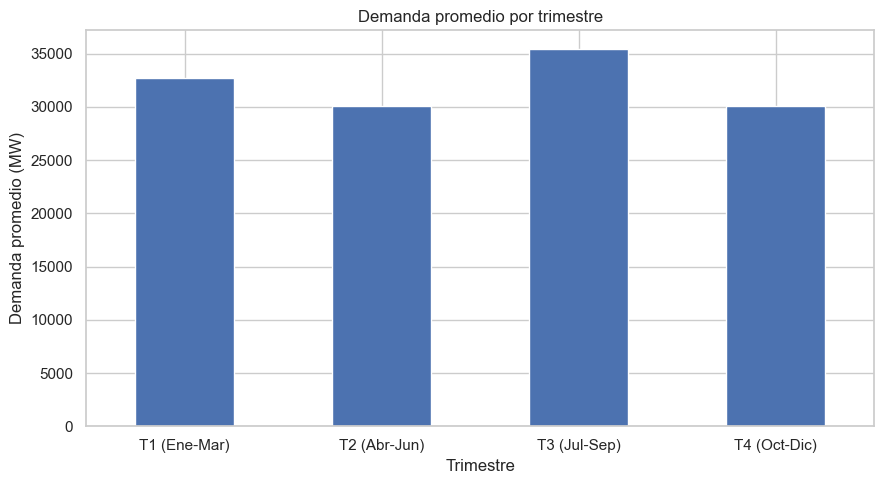

In [107]:
# PARTICIÓN TRIMESTRAL Promedio por trimestre calendario

trimestral = data.groupby("Quarter")["PJME_MW"].mean()

plt.figure(figsize=(9, 5))
trimestral.plot(kind="bar")
plt.title("Demanda promedio por trimestre")
plt.xlabel("Trimestre")
plt.ylabel("Demanda promedio (MW)")
plt.xticks(
    range(4),
    ["T1 (Ene-Mar)", "T2 (Abr-Jun)",
     "T3 (Jul-Sep)", "T4 (Oct-Dic)"],
    rotation=0
)
plt.tight_layout()
plt.show()

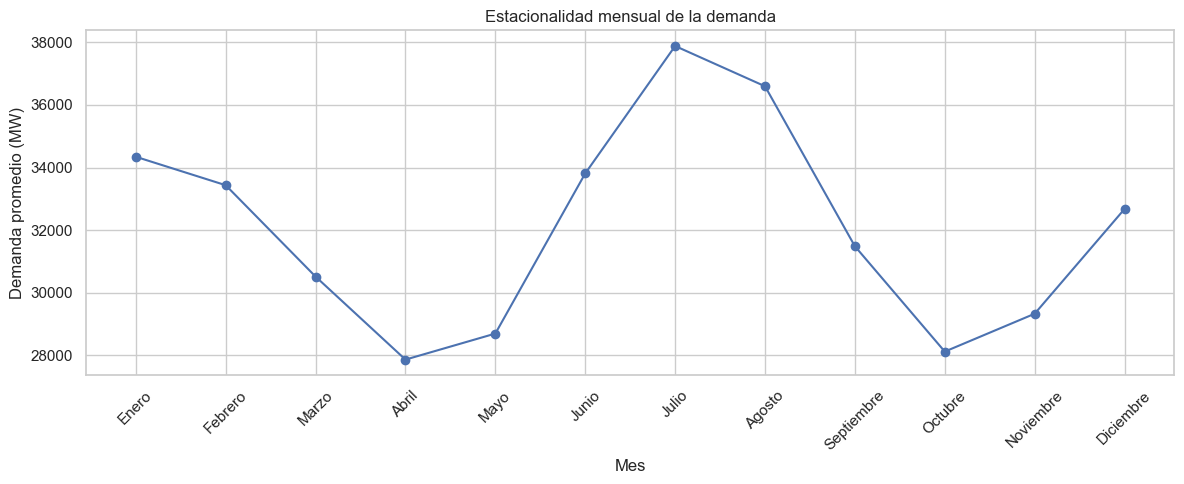

In [108]:
# PARTICIÓN MENSUAL Promedio de todos los eneros, febreros, etc.


mensual = data.groupby("Month")["PJME_MW"].mean()

plt.figure(figsize=(12, 5))
plt.plot(mensual.index, mensual.values, marker="o")
plt.title("Estacionalidad mensual de la demanda")
plt.xlabel("Mes")
plt.ylabel("Demanda promedio (MW)")
plt.xticks(range(1, 13), meses, rotation=45)
plt.tight_layout()
plt.show()

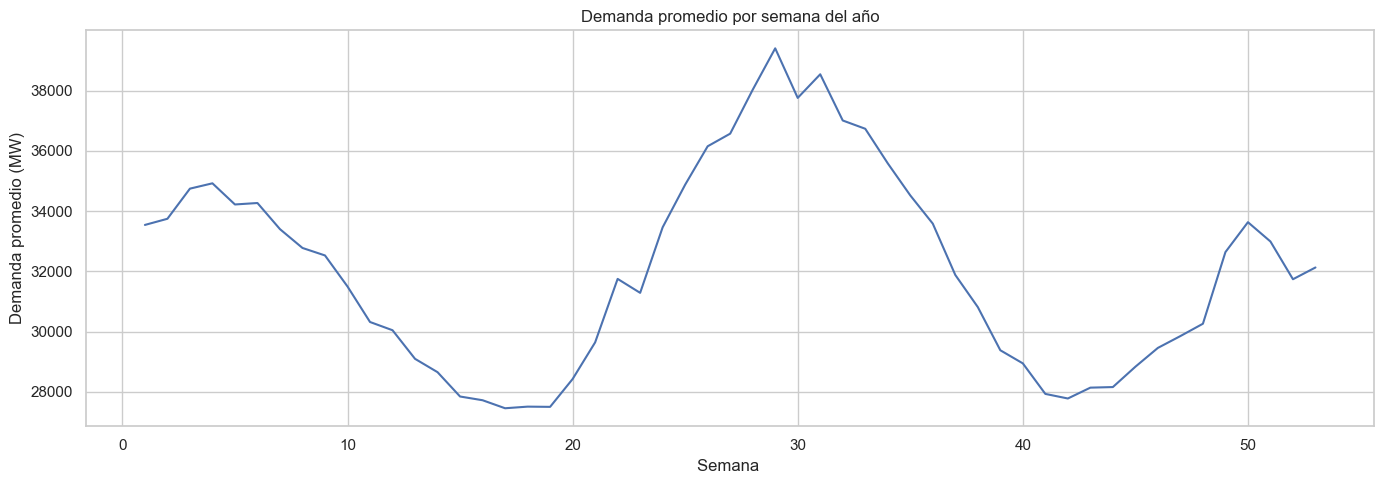

In [110]:
# PARTICIÓN SEMANAL Promedio por número de semana del año

semanal = data.groupby("Week")["PJME_MW"].mean()

plt.figure(figsize=(14, 5))
plt.plot(semanal.index, semanal.values)
plt.title("Demanda promedio por semana del año")
plt.xlabel("Semana ")
plt.ylabel("Demanda promedio (MW)")
plt.tight_layout()
plt.show()

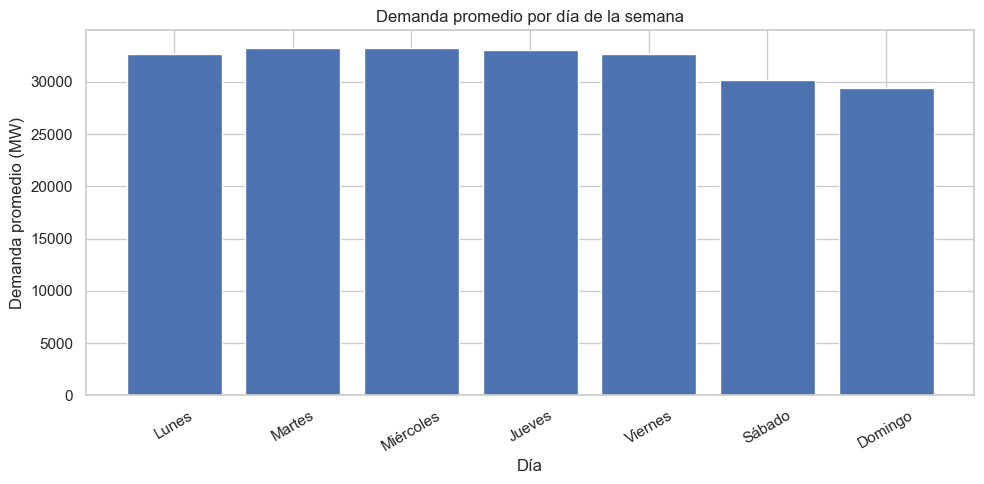

In [113]:
# PARTICIÓN POR DÍA DE LA SEMANA


diaria = data.groupby("DayOfWeek")["PJME_MW"].mean()

plt.figure(figsize=(10, 5))
plt.bar(dias, diaria.reindex(range(7)).values)
plt.title("Demanda promedio por día de la semana")
plt.xlabel("Día")
plt.ylabel("Demanda promedio (MW)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

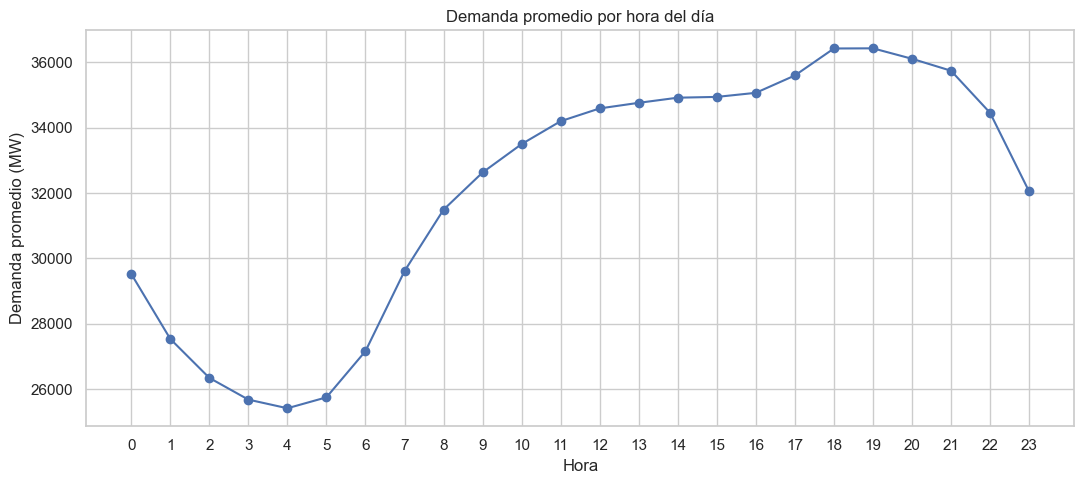

In [114]:
#  PARTICIÓN POR HORA DEL DÍA

horaria = data.groupby("Hour")["PJME_MW"].mean()

plt.figure(figsize=(11, 5))
plt.plot(horaria.index, horaria.values, marker="o")
plt.title("Demanda promedio por hora del día")
plt.xlabel("Hora")
plt.ylabel("Demanda promedio (MW)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()


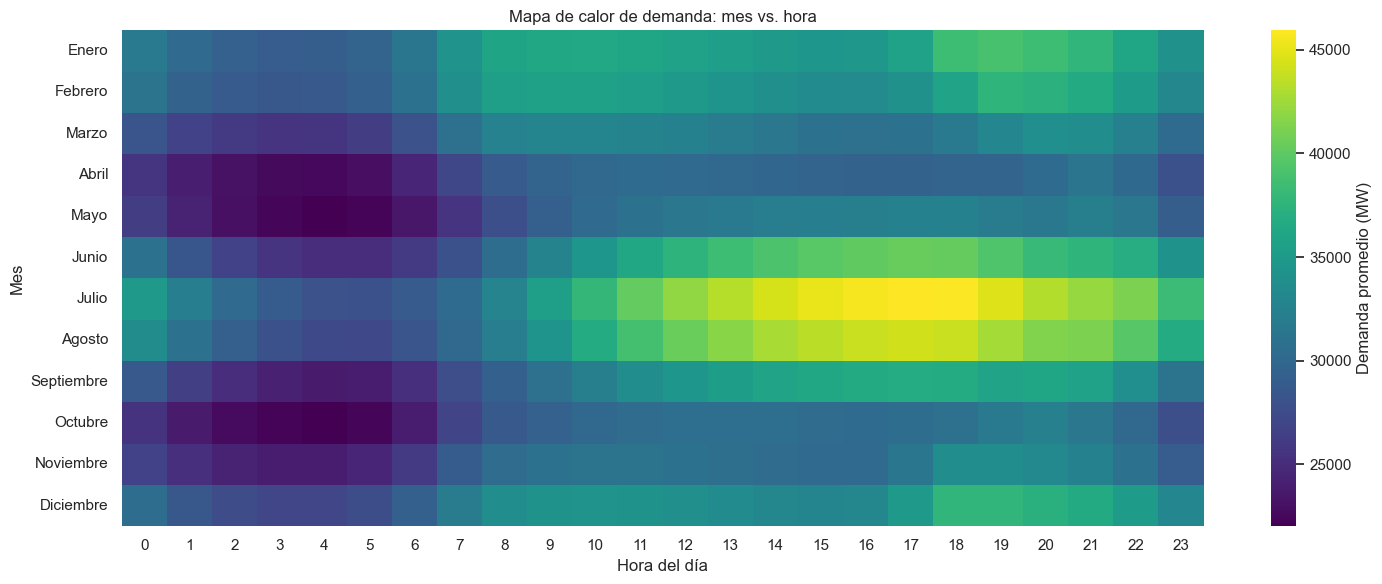

In [115]:
# MAPA DE CALOR: MES VS. HORA
import seaborn as sns

heatmap_data = data.pivot_table(
    values="PJME_MW",
    index="Month",
    columns="Hour",
    aggfunc="mean"
)

plt.figure(figsize=(15, 6))
sns.heatmap(
    heatmap_data,
    cmap="viridis",
    xticklabels=1,
    yticklabels=meses,
    cbar_kws={"label": "Demanda promedio (MW)"}
)
plt.title("Mapa de calor de demanda: mes vs. hora")
plt.xlabel("Hora del día")
plt.ylabel("Mes")
plt.tight_layout()
plt.show()

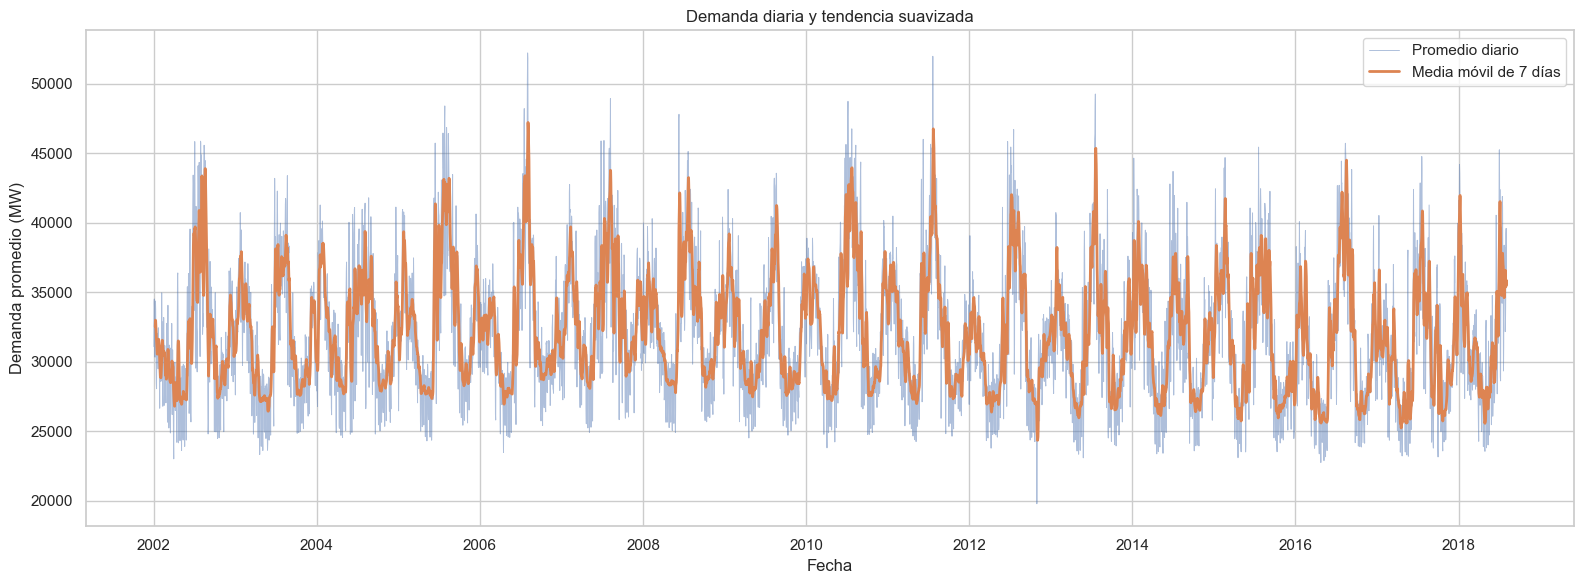

In [116]:
#  PROMEDIO DIARIO Y MEDIA MÓVIL DE 7 DÍAS

if "Datetime" in data.columns:
    serie_temporal = data.copy()
    serie_temporal["Datetime"] = pd.to_datetime(
        serie_temporal["Datetime"], errors="coerce"
    )
    serie_temporal = serie_temporal.set_index("Datetime")
else:
    serie_temporal = data.copy()
    if not isinstance(serie_temporal.index, pd.DatetimeIndex):
        serie_temporal.index = pd.to_datetime(
            serie_temporal.index, errors="coerce"
        )

diario_resample = (
    serie_temporal["PJME_MW"]
    .sort_index()
    .resample("D")
    .mean()
)
media_movil = diario_resample.rolling(
    window=7, min_periods=7
).mean()

plt.figure(figsize=(16, 6))
plt.plot(
    diario_resample.index,
    diario_resample.values,
    alpha=0.45,
    linewidth=0.7,
    label="Promedio diario"
)
plt.plot(
    media_movil.index,
    media_movil.values,
    linewidth=2,
    label="Media móvil de 7 días"
)
plt.title("Demanda diaria y tendencia suavizada")
plt.xlabel("Fecha")
plt.ylabel("Demanda promedio (MW)")
plt.legend()
plt.tight_layout()
plt.show()




In [118]:

import numpy as np
import pandas as pd
import plotly.graph_objects as go

# 1. Calcular la demanda promedio para cada mes y hora
demanda_3d = data.pivot_table(
    values="PJME_MW",
    index=data.Month,
    columns=data.Hour,
    aggfunc="mean"
)

# Garantizar que estén presentes los 12 meses y las 24 horas
demanda_3d = demanda_3d.reindex(
    index=range(1, 13),
    columns=range(1,24)
)

# 2. Crear las coordenadas
horas = np.arange(1,24)
meses = np.arange(1, 13)

X, Y = np.meshgrid(horas, meses)
Z = demanda_3d.to_numpy(dtype=float)

nombres_meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Sep", "Oct", "Nov", "Dic"
]

# 3. Crear la superficie interactiva
fig = go.Figure(
    data=[
        go.Surface(
            x=X,
            y=Y,
            z=Z,
            colorscale="Viridis",
            colorbar=dict(title="Demanda (MW)"),
            connectgaps=False,
            hovertemplate=(
                "Hora: %{x}:00<br>"
                "Mes: %{y}<br>"
                "Demanda: %{z:.2f} MW"
                "<extra></extra>"
            )
        )
    ]
)

# 4. Configurar la gráfica
fig.update_layout(
    title="Demanda eléctrica PJME_MW: superficie 3D interactiva",
    scene=dict(
        xaxis_title="Hora del día",
        yaxis_title="Mes del año",
        zaxis_title="Demanda promedio (MW)",
        xaxis=dict(dtick=1),
        yaxis=dict(
            tickmode="array",
            tickvals=list(range(1, 13)),
            ticktext=nombres_meses
        ),
        camera=dict(
            eye=dict(x=1.6, y=-1.6, z=1.1)
        )
    ),
    width=1100,
    height=750
)

# 5. Mostrar la gráfica
fig.show()


## Modelos ##

In [76]:
#pivotar cada fila es un dia y cada columna es una hora del día, el valor es la demanda promedio de esa hora en ese día
daily_profiles = data.pivot_table(index='Datetime', columns='hour', values='PJME_MW', aggfunc='mean')

In [119]:
# Eliminar días con horas faltantes (ej. cambios de horario DST)
daily_clean = daily_profiles.dropna().copy()

# Estandarizar cada hora (media 0, desviación estándar 1)
scaler = StandardScaler()
# Reagrupar las observaciones por fecha y hora
daily_profiles = (
    data.assign(Date=data.index.normalize())
        .pivot_table(
            index="Date",
            columns="Hour",
            values="PJME_MW",
            aggfunc="mean"
        )
        .reindex(columns=range(24))
)

# Eliminar días con horas faltantes, como los cambios de horario
daily_clean = daily_profiles.dropna().copy()

if daily_clean.empty:
    raise ValueError("No hay días completos con 24 horas para estandarizar.")

X_scaled = scaler.fit_transform(daily_clean)

Determinar el numero de perfiles K

In [79]:
K_range = range(2, 9)
inertias, silhouettes, aics, bics = [], [], [], []

for k in K_range:
    # K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    
    # GMM con Expectation-Maximization (EM)
    gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=42, n_init=5)
    gmm.fit(X_scaled)
    aics.append(gmm.aic(X_scaled))
    bics.append(gmm.bic(X_scaled))

c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Usuario\AppData\Local\Programs\Python\Python312\L

Entrenamiento

In [80]:
from sklearn.neural_network import MLPRegressor

# A) K-Means (K=3 perfiles principales)
km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = km_final.fit_predict(X_scaled)
# Distancia euclidiana al centroide más cercano
km_dist = np.min(km_final.transform(X_scaled), axis=1)

# B) GMM (K=4 para capturar mayor flexibilidad en covarianzas)
gmm_final = GaussianMixture(n_components=4, covariance_type='full', random_state=42, n_init=5)
gmm_labels = gmm_final.fit_predict(X_scaled)
# Log-verosimilitud por día (valores más negativos = días más improbables/anómalos)
gmm_log_prob = gmm_final.score_samples(X_scaled)

# C) Autoencoder (Arquitectura simétrica: 24 -> 12 -> 4 -> 12 -> 24)
autoencoder = MLPRegressor(
    hidden_layer_sizes=(12, 4, 12),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)
autoencoder.fit(X_scaled, X_scaled)
X_reconstructed = autoencoder.predict(X_scaled)
# Error cuadrático medio de reconstrucción por día
ae_mse = np.mean((X_scaled - X_reconstructed) ** 2, axis=1)

Consolidacion y criterio de la anomalia

In [87]:
from IPython.display import display

results = pd.DataFrame({
    'Perfil_KMeans': km_labels,
    'Dist_KMeans': km_dist,
    'Perfil_GMM': gmm_labels,
    'LogProb_GMM': gmm_log_prob,
    'Error_AE': ae_mse,
    'Consumo_Medio_MW': daily_clean.mean(axis=1),
    'Pico_Max_MW': daily_clean.max(axis=1)
}, index=daily_clean.index)

# Definir umbral en el 1% más extremo de cada métrica (Percentil 99 o 1)
results['Anom_KM'] = results['Dist_KMeans'] > np.percentile(results['Dist_KMeans'], 99)
results['Anom_GMM'] = results['LogProb_GMM'] < np.percentile(results['LogProb_GMM'], 1)
results['Anom_AE'] = results['Error_AE'] > np.percentile(results['Error_AE'], 99)

# Puntuación de consenso (0 a 3 modelos coinciden en que el día es anómalo)
results['Consenso_Anomalia'] = (
    results['Anom_KM'].astype(int) + 
    results['Anom_GMM'].astype(int) + 
    results['Anom_AE'].astype(int)
)
#Dataframe para resumen de perfiles
resumen_perfiles = (
    results.groupby('Perfil_KMeans')
    .agg(
        Total_Dias=('Consumo_Medio_MW', 'count'),
        Porcentaje_Dias=('Consumo_Medio_MW', lambda x: len(x) / len(results) * 100),
        Consumo_Medio_MW=('Consumo_Medio_MW', 'mean'),
        Pico_Max_Medio_MW=('Pico_Max_MW', 'mean'),
        Dias_Anomalos_AE=('Anom_AE', 'sum')
    )
    .reset_index()
    .round(2)
)
#Dataframe para el top 10 anomalias
top_anomalias = (
    results.sort_values('Error_AE', ascending=False)
    .head(10)
    .reset_index()
    .rename(columns={'Date': 'Fecha'})
    [['Fecha', 'Perfil_KMeans', 'Consumo_Medio_MW', 'Pico_Max_MW', 'Error_AE', 'LogProb_GMM', 'Consenso_Anomalia']]
    .round({'Consumo_Medio_MW': 1, 'Pico_Max_MW': 1, 'Error_AE': 4, 'LogProb_GMM': 2})
)


print("RESUMEN DE PERFILES DE CONSUMO (K-MEANS)")
display(resumen_perfiles)

print("\n TOP 10 DÍAS ANÓMALOS (AUTOENCODER) ")
display(top_anomalias)


RESUMEN DE PERFILES DE CONSUMO (K-MEANS)


,Perfil_KMeans,Total_Dias,Porcentaje_Dias,Consumo_Medio_MW,Pico_Max_Medio_MW,Dias_Anomalos_AE
0,0,1060,17.59,39791.30,47861.75,34
1,1,2653,44.02,28039.29,32243.07,4
2,2,2314,38.39,33237.56,38728.42,23



 TOP 10 DÍAS ANÓMALOS (AUTOENCODER) 


,Fecha,Perfil_KMeans,Consumo_Medio_MW,Pico_Max_MW,Error_AE,LogProb_GMM,Consenso_Anomalia
0,2012-10-30,1,19769.0,24824.0,0.8241,25.41,2
1,2010-07-25,0,41753.9,51671.0,0.4550,-9.42,2
2,2012-10-29,1,25123.4,30284.0,0.3717,7.07,2
3,2012-06-22,0,43250.0,52600.0,0.3161,24.25,1
4,2009-08-21,0,43349.0,53674.0,0.2827,22.73,1
5,2004-08-21,2,35298.0,41497.0,0.2701,19.23,2
6,2016-06-11,1,30613.9,41298.0,0.2571,33.90,1
7,2009-07-31,0,38750.9,47956.0,0.2539,25.17,1
8,2012-07-18,0,46715.4,58999.0,0.2404,24.97,2
9,2011-09-15,2,32843.1,37966.0,0.2210,26.99,1


Comparacion K-means & GMM

In [90]:
from sklearn.metrics import adjusted_rand_score

metrics = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=42, n_init=5).fit(X_scaled)
    
    km_lbl = km.predict(X_scaled)
    gmm_lbl = gmm.predict(X_scaled)
    
    metrics.append({
        'K': k,
        'KM_Inercia': round(km.inertia_, 1),
        'KM_Silueta': round(silhouette_score(X_scaled, km_lbl), 4),
        'GMM_Silueta': round(silhouette_score(X_scaled, gmm_lbl), 4),
        'GMM_AIC': round(gmm.aic(X_scaled), 1),
        'GMM_BIC': round(gmm.bic(X_scaled), 1),
        'Concordancia_ARI': round(adjusted_rand_score(km_lbl, gmm_lbl), 4)
    })

df_metrics = pd.DataFrame(metrics)
display(df_metrics)

,K,KM_Inercia,KM_Silueta,GMM_Silueta,GMM_AIC,GMM_BIC,Concordancia_ARI
0,2,63697.0,0.4762,0.0938,-444955.6,-440604.7,0.0703
1,3,43650.6,0.3839,0.1151,-474469.9,-467940.2,0.1670
2,4,35726.5,0.3512,0.0643,-487539.7,-478831.2,0.1513
3,5,29341.4,0.3312,-0.0015,-493124.5,-482237.2,0.1866
4,6,24778.8,0.3175,-0.0376,-493172.0,-480105.9,0.1577
5,7,21340.9,0.3286,-0.0523,-496458.5,-481213.6,0.1650
6,8,19298.6,0.3086,-0.0342,-503786.3,-486362.6,0.1928


Modelos Finales & AE score anomalia

In [96]:
metrics = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=42, n_init=5).fit(X_scaled)
    metrics.append({
        'K': k,
        'KM_Silueta': silhouette_score(X_scaled, km.predict(X_scaled)),
        'GMM_BIC': gmm.bic(X_scaled)
    })
df_metrics = pd.DataFrame(metrics)

# Modelos finales y Autoencoder
km3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
gmm4 = GaussianMixture(n_components=4, covariance_type='full', random_state=42, n_init=5).fit(X_scaled)

ae = MLPRegressor(hidden_layer_sizes=(12, 4, 12), activation='relu', solver='adam', max_iter=500, random_state=42)
ae.fit(X_scaled, X_scaled)
ae_mse = np.mean((X_scaled - ae.predict(X_scaled)) ** 2, axis=1)

# Cruce con calendario y asignación de nombres
cal = pd.DataFrame(index=pd.to_datetime(daily_clean.index))
cal['Mes'] = cal.index.month
cal['KM_3'] = km3.predict(X_scaled)
cal['GMM_4'] = gmm4.predict(X_scaled)
cal['Consumo_Medio_MW'] = daily_clean.mean(axis=1).values
cal['Puntaje_Anomalia_AE'] = ae_mse

km_nombres = {
    0: 'P0: Pico Verano Laboral (39.8 GW)',
    1: 'P1: Templado / Finde (28.0 GW)',
    2: 'P2: Invierno / Carga Media (33.2 GW)'
}
gmm_nombres = {
    0: 'G0: Invierno Pleno',
    1: 'G1: Verano Pleno',
    2: 'G2: Transición / Atípico',
    3: 'G3: Entretiempo (Abr/Oct)'
}
cal['Nombre_Perfil_KM'] = cal['KM_3'].map(km_nombres)
cal['Nombre_Perfil_GMM'] = cal['GMM_4'].map(gmm_nombres)

## Visualizacion ##

In [99]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neural_network import MLPRegressor

km3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
gmm4 = GaussianMixture(n_components=4, covariance_type='full', random_state=42, n_init=5).fit(X_scaled)

ae = MLPRegressor(hidden_layer_sizes=(12, 4, 12), activation='relu', solver='adam', max_iter=500, random_state=42)
ae.fit(X_scaled, X_scaled)
ae_mse = np.mean((X_scaled - ae.predict(X_scaled)) ** 2, axis=1)

# Cruce con calendario y asignación de nombres
cal = pd.DataFrame(index=pd.to_datetime(daily_clean.index))
cal['Mes'] = cal.index.month
cal['KM_3'] = km3.predict(X_scaled)
cal['GMM_4'] = gmm4.predict(X_scaled)
cal['Consumo_Medio_MW'] = daily_clean.mean(axis=1).values
cal['Puntaje_Anomalia_AE'] = ae_mse

km_nombres = {
    0: 'P0: Pico Verano Laboral (39.8 GW)',
    1: 'P1: Templado / Finde (28.0 GW)',
    2: 'P2: Invierno / Carga Media (33.2 GW)'
}
gmm_nombres = {
    0: 'G0: Invierno Pleno',
    1: 'G1: Verano Pleno',
    2: 'G2: Transición / Atípico',
    3: 'G3: Entretiempo (Abr/Oct)'
}
cal['Nombre_Perfil_KM'] = cal['KM_3'].map(km_nombres)
cal['Nombre_Perfil_GMM'] = cal['GMM_4'].map(gmm_nombres)

# ==========================================
# GRÁFICO 1: SELECCIÓN DE K (SILUETA VS BIC)
# ==========================================
fig1 = make_subplots(specs=[[{"secondary_y": True}]])

fig1.add_trace(
    go.Scatter(
        x=df_metrics['K'], y=df_metrics['KM_Silueta'],
        name="Silueta (K-Means)", mode="lines+markers",
        line=dict(color="#1f77b4", width=3), marker=dict(size=9)
    ),
    secondary_y=False
)

fig1.add_trace(
    go.Scatter(
        x=df_metrics['K'], y=df_metrics['GMM_BIC'],
        name="BIC (GMM)", mode="lines+markers",
        line=dict(color="#d62728", width=3, dash="dot"), marker=dict(size=9, symbol="square")
    ),
    secondary_y=True
)

fig1.add_vline(x=3, line_dash="dash", line_color="gray", annotation_text="K=3 (Óptimo Silueta)", annotation_position="top right")
fig1.add_vline(x=4, line_dash="dash", line_color="#d62728", annotation_text="K=4 (Codo BIC)", annotation_position="bottom right")

fig1.update_layout(
    title="<b>1. Selección del Número de Perfiles (K): Silueta vs. BIC</b>",
    template="plotly_white",
    height=450,
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)
fig1.update_xaxes(title_text="Número de Perfiles (K)", dtick=1)
fig1.update_yaxes(title_text="Coeficiente de Silueta (K-Means)", secondary_y=False, color="#1f77b4")
fig1.update_yaxes(title_text="BIC GMM (Menor = Mejor ajuste)", secondary_y=True, color="#d62728")
fig1.show()

# ==========================================
# GRÁFICO 2: IDENTIDAD ESTACIONAL (HEATMAP GMM)
# ==========================================
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
orden_gmm = ['G1: Verano Pleno', 'G0: Invierno Pleno', 'G3: Entretiempo (Abr/Oct)', 'G2: Transición / Atípico']
ct_mes = (pd.crosstab(cal['Nombre_Perfil_GMM'], cal['Mes'], normalize='index') * 100).reindex(orden_gmm)

fig2 = px.imshow(
    ct_mes.values,
    x=meses,
    y=ct_mes.index,
    text_auto=".0f",
    color_continuous_scale="YlGnBu",
    aspect="auto",
    labels=dict(x="Mes del Año", y="", color="% del Grupo")
)
fig2.update_traces(texttemplate="%{z:.0f}%", textfont=dict(size=12))
fig2.update_layout(
    title="<b>2. Identidad Estacional de Perfiles GMM (Cruce con Calendario)</b>",
    template="plotly_white",
    height=420,
    margin=dict(l=200)
)
fig2.show()

# ==========================================
# GRÁFICO 3: CURVAS HORARIAS POR PERFIL NOMBRADO
# ==========================================
daily_plot = daily_clean.copy()
daily_plot['Perfil'] = cal['Nombre_Perfil_KM'].values
orden_km = ['P0: Pico Verano Laboral (39.8 GW)', 'P2: Invierno / Carga Media (33.2 GW)', 'P1: Templado / Finde (28.0 GW)']
curvas = daily_plot.groupby('Perfil').mean().reindex(orden_km)

fig3 = go.Figure()
colores_km = ['#d62728', '#ff7f0e', '#2ca02c']

for (nombre, fila), color in zip(curvas.iterrows(), colores_km):
    fig3.add_trace(go.Scatter(
        x=list(range(24)),
        y=fila.values,
        mode='lines+markers',
        name=nombre,
        line=dict(width=3, color=color),
        marker=dict(size=7),
        hovertemplate="Hora: %{x}:00h<br>Consumo: %{y:,.0f} MW<extra></extra>"
    ))

fig3.update_layout(
    title="<b>3. Curvas Horarias Promedio por Perfil Operativo (K-Means K=3)</b>",
    xaxis_title="Hora del Día (0 - 23h)",
    yaxis_title="Consumo Medio (MW)",
    template="plotly_white",
    height=460,
    hovermode="x unified",
    xaxis=dict(dtick=2),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)
fig3.show()

# ==========================================
# GRÁFICO 4: PUNTAJE DE ANOMALÍA AUTOENCODER
# ==========================================
umbral_p99 = np.percentile(cal['Puntaje_Anomalia_AE'], 99)
cal['Estado'] = np.where(cal['Puntaje_Anomalia_AE'] > umbral_p99, 'Anómalo (> P99)', 'Normal')

# Corrección: nombrar el eje del índice antes de resetearlo
df_ae_plot = cal.rename_axis('Fecha').reset_index()

fig4 = px.scatter(
    df_ae_plot,
    x='Fecha',
    y='Puntaje_Anomalia_AE',
    color='Estado',
    hover_data={'Nombre_Perfil_KM': True, 'Consumo_Medio_MW': ':.0f', 'Puntaje_Anomalia_AE': ':.4f'},
    color_discrete_map={'Normal': 'rgba(70, 130, 180, 0.45)', 'Anómalo (> P99)': '#dc143c'},
    labels={'Fecha': 'Fecha (2002 - 2018)', 'Puntaje_Anomalia_AE': 'Error de Reconstrucción (MSE)'}
)

fig4.add_hline(
    y=umbral_p99,
    line_dash="dash",
    line_color="darkred",
    annotation_text=f"Umbral P99 ({umbral_p99:.3f})",
    annotation_position="top left"
)

# Anotar Top 3 con flechas separadas para evitar solapamiento
top3 = df_ae_plot.sort_values('Puntaje_Anomalia_AE', ascending=False).head(3)
offsets = [(45, 0), (45, -15), (45, 15)]
for (_, row), (ax_off, ay_off) in zip(top3.iterrows(), offsets):
    fig4.add_annotation(
        x=row['Fecha'],
        y=row['Puntaje_Anomalia_AE'],
        text=f"<b>{row['Fecha'].strftime('%Y-%m-%d')}</b> ({row['Puntaje_Anomalia_AE']:.2f})",
        showarrow=True,
        arrowhead=2,
        ax=ax_off,
        ay=ay_off,
        font=dict(color="darkred", size=11)
    )

fig4.update_layout(
    title="<b>4. Detección de Días Anómalos mediante Autoencoder (MSE)</b>",
    template="plotly_white",
    height=480,
    yaxis=dict(range=[-0.02, 0.92]),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)
fig4.show()